**Name:** Sandeep Reddy Banda  
**Course:** Advanced Big Data and Data Mining (MSCS 634)  
**University:** University of the Cumberlands  
**Instructor:** Satish Penmatsa  
**Lab Assignment:** Lab 2 – Classification Using KNN and RNN Algorithms

## Introduction
In this lab I compare two neighbor-based classifiers, K-Nearest Neighbors (KNN) and Radius Neighbors (RNN), on the Wine dataset from scikit-learn. I try different values of `k` for KNN and different radius values for RNN, then look at how accuracy changes.

## Step 1: Load and Prepare the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

wine = load_wine()
X, y = wine.data, wine.target
df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [2]:
print("Shape:", X.shape)
print("Classes:", wine.target_names)
print("\nClass distribution:")
print(df['target'].value_counts().sort_index())
print("\nMissing values:", df.isnull().sum().sum())

Shape: (178, 13)
Classes: ['class_0' 'class_1' 'class_2']

Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64

Missing values: 0


In [3]:
df.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


**Observations:** The dataset has 178 samples, 13 numeric features and 3 classes (59, 71 and 48 samples), so the classes are fairly balanced and there are no missing values. The feature scales are very different, though. `proline` goes from about 278 to 1680, while features like `hue` and `nonflavanoid_phenols` stay below 3. This matters a lot for distance-based models, and I come back to it later.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])

Training size: 142
Testing size: 36


## Step 2: K-Nearest Neighbors (KNN)

In [5]:
k_values = [1, 5, 11, 15, 21]
knn_acc = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    knn_acc.append(acc)

knn_results = pd.DataFrame({'k': k_values, 'accuracy': knn_acc})
knn_results

,k,accuracy
0,1,0.777778
1,5,0.722222
2,11,0.750000
3,15,0.750000
4,21,0.777778


## Step 3: Radius Neighbors (RNN)

One decision I had to make here: with a fixed radius, a test point can end up with no training points inside it, and `RadiusNeighborsClassifier` throws an error in that case. I set `outlier_label='most_frequent'` so those points get the most common class instead.

In [6]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_acc = []

for r in radius_values:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent')
    rnn.fit(X_train, y_train)
    acc = accuracy_score(y_test, rnn.predict(X_test))
    rnn_acc.append(acc)

rnn_results = pd.DataFrame({'radius': radius_values, 'accuracy': rnn_acc})
rnn_results

,radius,accuracy
0,350,0.750000
1,400,0.722222
2,450,0.722222
3,500,0.722222
4,550,0.722222
5,600,0.722222


In [7]:
# Extra check: how many training points fall inside each radius on average?
for r in radius_values:
    nn = RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent').fit(X_train, y_train)
    neigh = nn.radius_neighbors(X_test, return_distance=False)
    counts = [len(n) for n in neigh]
    print(f"radius={r}: avg neighbors={np.mean(counts):.1f}, test points with none={sum(c == 0 for c in counts)}")

radius=350: avg neighbors=78.1, test points with none=0
radius=400: avg neighbors=85.9, test points with none=0
radius=450: avg neighbors=93.2, test points with none=0
radius=500: avg neighbors=98.9, test points with none=0
radius=550: avg neighbors=104.4, test points with none=0
radius=600: avg neighbors=109.9, test points with none=0


## Step 4: Visualize and Compare Results

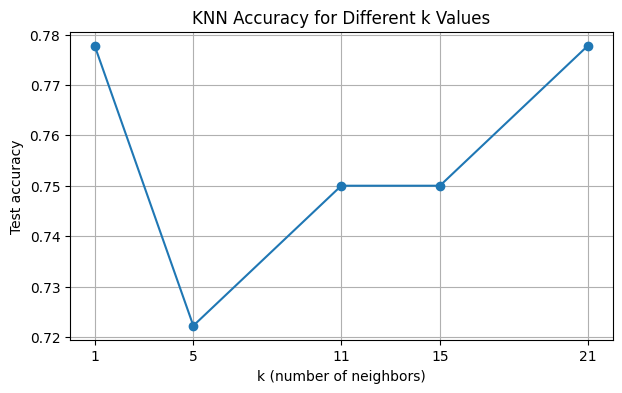

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(k_values, knn_acc, marker='o')
plt.title('KNN Accuracy for Different k Values')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Test accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

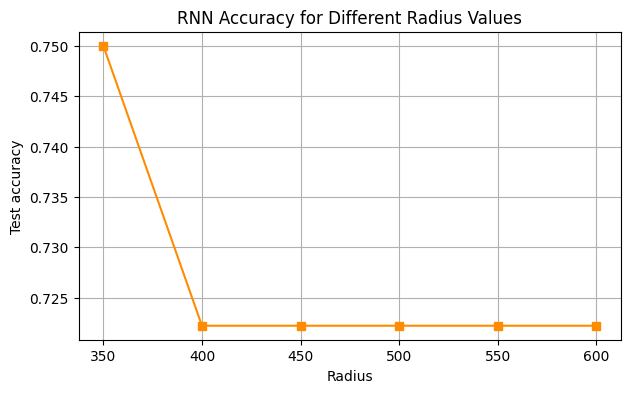

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(radius_values, rnn_acc, marker='s', color='darkorange')
plt.title('RNN Accuracy for Different Radius Values')
plt.xlabel('Radius')
plt.ylabel('Test accuracy')
plt.xticks(radius_values)
plt.grid(True)
plt.show()

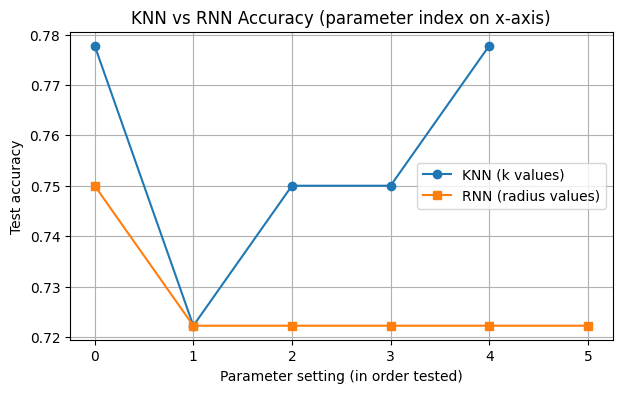

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(range(len(k_values)), knn_acc, marker='o', label='KNN (k values)')
plt.plot(range(len(radius_values)), rnn_acc, marker='s', label='RNN (radius values)')
plt.title('KNN vs RNN Accuracy (parameter index on x-axis)')
plt.xlabel('Parameter setting (in order tested)')
plt.ylabel('Test accuracy')
plt.legend()
plt.grid(True)
plt.show()

### Extra check: does feature scaling change things?
Since `proline` seemed to dominate the distances, I tried the same KNN values again after standardizing the features. This is not part of the required steps, I just wanted to test my guess.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

scaled_acc = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k).fit(Xs_train, y_train)
    scaled_acc.append(accuracy_score(y_test, knn.predict(Xs_test)))

pd.DataFrame({'k': k_values, 'unscaled': knn_acc, 'scaled': scaled_acc})

,k,unscaled,scaled
0,1,0.777778,0.944444
1,5,0.722222,0.944444
2,11,0.750000,0.944444
3,15,0.750000,0.972222
4,21,0.777778,0.944444


## Comparison and Observations

**KNN:** Accuracy stayed between about 72% and 78% for every k I tried. The best results were at k = 1 and k = 21 (both 77.8%), and the lowest was k = 5 (72.2%). There is no clean upward or downward trend, it just bounces around. The test set only has 36 samples, so one sample is about 2.8%, and the differences between k values are only 1 or 2 predictions. I would not read too much into which k is "best" from one split.

**RNN:** Accuracy was 75% at radius 350 and then went flat at 72.2% for every radius from 400 to 600. The extra check shows why. Even at radius 350, a test point already has around 78 of the 142 training points inside its radius, and at 600 it is about 110. With that many neighbors, the vote is basically dominated by the largest classes, so making the radius bigger stops changing the predictions. This is like using a very large k in KNN.

**Comparing them:** Neither model did great here, and both landed in the same 72–78% range. The best KNN result (77.8%) was slightly higher than the best RNN result (75%), but that is only one prediction apart. The main reason for the low scores is the scale problem I noticed in Step 1. In the extra check, standardizing the features raised KNN accuracy to about 94–97% for all k values. So the choice of feature scaling mattered a lot more than the choice of k or radius.

**When to prefer each one:**
- KNN is easier to use when I do not know how far apart points are, because it always gets exactly k neighbors. That makes it a safer default, especially when the data is unevenly spread.
- RNN makes more sense when distance has a real meaning and the density of points is uneven, since it uses more neighbors in dense areas and fewer in sparse ones. The downside is that the radius has to match the scale of the data. Here the radii of 350 to 600 were only sensible because `proline` dominated the distances, and I needed `outlier_label` to handle points with no neighbors.

**Limitations:** I used one train/test split with `random_state=42`. Cross-validation would give a more reliable comparison.